# 📈 Carbono en tránsito — Parte 3: modelo, interpretación y conclusiones

**Autora de esta parte:** Michelle Andrea Murillo Gonzalez (ID: 37858)

**Integrantes del grupo:** Luis Fabián Ulloa Rodríguez (45210) · Luis Andrés Santos Cortés (45297) · Michelle Andrea Murillo Gonzalez (37858)


**Pregunta del proyecto:** ¿Colombia es importador o exportador neto de CO₂ por el comercio, y cómo ha cambiado desde 1990 hasta el último año disponible?

**Gráfico del artículo usado:** *Share of CO₂ emissions embedded in trade*, del artículo [CO₂ and Greenhouse Gas Emissions](https://ourworldindata.org/co2-emissions) de Our World in Data. Datos: [enlace del gráfico](https://ourworldindata.org/grapher/share-co2-embedded-in-trade).

**¿Cómo se lee el dato?**
- **Positivo:** el país importa más CO₂ del que exporta (importador neto).
- **Negativo:** el país exporta más CO₂ del que importa (exportador neto).
- Está dado como **% de las emisiones que el país produce**.

> 💡 **Cómo leer este cuaderno:** antes de cada bloque de código hay un texto que explica *qué hace*. Dentro del código, cada línea con `#` es un comentario que explica el paso. Para ejecutar un bloque: selecciónalo y presiona **Shift + Enter**. Se ejecutan **en orden, de arriba hacia abajo**.

> Este cuaderno es una de las 3 partes. Parte 1: carga y limpieza (Luis Fabián). Parte 2: visualización (Luis Andrés).

## 1. Librerías
**¿Qué hace?** Una librería es una caja de herramientas ya hecha. Las importamos para no programar todo desde cero.

In [1]:
import pandas as pd                                          # pandas: tablas de datos
import matplotlib.pyplot as plt                              # matplotlib: gráficos
from sklearn.linear_model import LinearRegression            # el modelo de regresión lineal
from sklearn.metrics import r2_score, mean_absolute_error    # medidas para evaluar el modelo

## 2. Cargar los datos
**¿Qué hace?** Descarga el archivo CSV directamente de Our World in Data y lo convierte en una tabla llamada `datos`. Se necesita internet.

*Si no hay internet:* descarga el CSV desde la página del gráfico (botón *Download*), ponlo en la misma carpeta y cambia la línea de `pd.read_csv(...)` por `datos = pd.read_csv("emisiones_comercio_co2.csv")`.

In [2]:
# Enlace del archivo CSV de Our World in Data
url = "https://ourworldindata.org/grapher/share-co2-embedded-in-trade.csv?v=1&csvType=full&useColumnShortNames=false"

# Leemos el archivo y lo guardamos en la variable "datos"
datos = pd.read_csv(url, storage_options={"User-Agent": "Our World In Data data fetch/1.0"})

# Guardamos una copia en el computador (por si luego no hay internet)
datos.to_csv("emisiones_comercio_co2.csv", index=False)

# Mostramos las primeras 5 filas
datos.head()

,Entity,Code,Year,Share of annual CO₂ emissions embedded in trade
0,Africa,OWID_AFR,1990,-1.149361
1,Africa,OWID_AFR,1991,-2.982905
2,Africa,OWID_AFR,1992,-0.305387
3,Africa,OWID_AFR,1993,-1.342971
4,Africa,OWID_AFR,1994,-2.414056


## 3. Limpieza rápida
**¿Qué hace?** Es la misma limpieza de la Parte 1: nombres simples, sin repetidos ni vacíos, y solo Colombia.

In [3]:
# 1. Ponemos nombres de columnas más simples
datos.columns = ["pais", "codigo", "año", "porcentaje"]

# 2. Quitamos filas repetidas
datos = datos.drop_duplicates()

# 3. Quitamos filas que no tienen valor en "porcentaje"
datos = datos.dropna(subset=["porcentaje"])

# 4. Nos quedamos solo con Colombia y la ordenamos por año
colombia = datos[datos["pais"] == "Colombia"].sort_values("año")

print("Filas totales después de limpiar:", len(datos))
print("Años de datos de Colombia:", len(colombia))
colombia.head()

Filas totales después de limpiar: 4851
Años de datos de Colombia: 35


,pais,codigo,año,porcentaje
875,Colombia,COL,1990,6.006888
876,Colombia,COL,1991,4.837586
877,Colombia,COL,1992,8.713652
878,Colombia,COL,1993,7.575504
879,Colombia,COL,1994,6.829249


## 4. Modelo de regresión lineal
**¿Qué hace?** Busca la línea recta que muestra cómo cambia el porcentaje con los años. Se entrena con el 80 % de los años y se prueba con el 20 % final.

In [4]:
# X = lo que usamos para predecir (el año). y = lo que queremos predecir (el porcentaje)
X = colombia[["año"]]
y = colombia["porcentaje"]

# Separamos: 80% de los años para entrenar y el 20% final para probar
corte = int(len(X) * 0.8)
X_train, X_test = X[:corte], X[corte:]
y_train, y_test = y[:corte], y[corte:]

# Creamos el modelo y lo entrenamos con los datos de entrenamiento
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print("Entrenó con los años", X_train["año"].min(), "a", X_train["año"].max())
print("Se probará con los años", X_test["año"].min(), "a", X_test["año"].max())
print(f"Según el modelo, el porcentaje cambia {modelo.coef_[0]:.2f} puntos cada año.")

Entrenó con los años 1990 a 2017
Se probará con los años 2018 a 2024
Según el modelo, el porcentaje cambia 0.76 puntos cada año.


**Evaluación del modelo.** Mide qué tan bien predice los años de prueba.

In [5]:
# El modelo predice los años de prueba y comparamos con los valores reales
predicciones = modelo.predict(X_test)

r2 = r2_score(y_test, predicciones)                  # qué tan bien se ajusta (1 = perfecto)
error = mean_absolute_error(y_test, predicciones)    # cuánto se equivoca en promedio

print(f"R² = {r2:.2f}")
print(f"Error promedio = {error:.1f} puntos porcentuales")

if r2 >= 0.5:
    print("Resultado: el modelo describe bien los años de prueba.")
else:
    print("Resultado: el modelo describe de forma limitada los años de prueba (la tendencia no es una recta perfecta).")

R² = -33.06
Error promedio = 10.8 puntos porcentuales
Resultado: el modelo describe de forma limitada los años de prueba (la tendencia no es una recta perfecta).


**Línea del modelo con todos los años.**

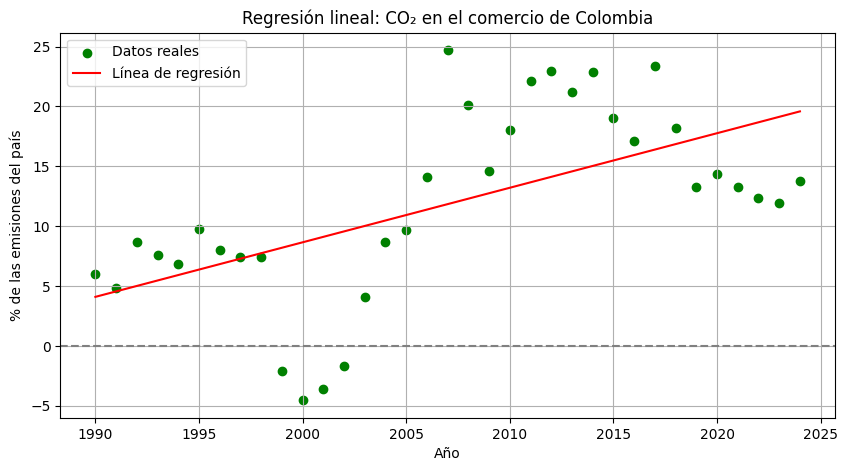

In [6]:
# Ahora entrenamos el modelo con TODOS los años para dibujar la línea final
modelo_final = LinearRegression()
modelo_final.fit(X, y)

plt.figure(figsize=(10, 5))
plt.scatter(X["año"], y, color="green", label="Datos reales")                         # puntos reales
plt.plot(X["año"], modelo_final.predict(X), color="red", label="Línea de regresión")  # línea del modelo
plt.axhline(0, color="gray", linestyle="--")
plt.title("Regresión lineal: CO₂ en el comercio de Colombia")
plt.xlabel("Año")
plt.ylabel("% de las emisiones del país")
plt.legend()
plt.grid(True)
plt.show()

**Predicción.** Es solo una estimación: el comercio mundial cambia por muchos motivos que el modelo no conoce.

In [7]:
# Años del futuro que queremos estimar
futuro = pd.DataFrame({"año": [2030, 2035]})

for año, valor in zip(futuro["año"], modelo_final.predict(futuro)):
    print(f"Estimación para {año}: {valor:.1f} %")

Estimación para 2030: 22.3 %
Estimación para 2035: 24.6 %


## 5. Interpretación de los resultados
Estas frases se calculan con los resultados de este mismo cuaderno, así siempre coinciden con los números.

In [8]:
pendiente = modelo_final.coef_[0]        # cuánto cambia el porcentaje por año
r2_total = modelo_final.score(X, y)      # R² usando todos los años
promedio = colombia["porcentaje"].mean() # promedio de todos los años
ultimo = colombia.iloc[-1]               # último año disponible

# Frase 1: último año
tipo = "importador neto" if ultimo["porcentaje"] > 0 else "exportador neto"
print(f"- En {int(ultimo['año'])} Colombia fue {tipo} de CO₂ ({ultimo['porcentaje']:.1f} % de sus emisiones).")

# Frase 2: promedio
tipo_prom = "importador neto" if promedio > 0 else "exportador neto"
print(f"- En promedio, Colombia fue {tipo_prom} ({promedio:.1f} %).")

# Frase 3: tendencia
if pendiente > 0:
    print(f"- La tendencia SUBE {pendiente:.2f} puntos por año: Colombia se vuelve más importador (o menos exportador).")
else:
    print(f"- La tendencia BAJA {abs(pendiente):.2f} puntos por año: Colombia se vuelve menos importador (o más exportador).")

# Frases 4 y 5: calidad del modelo
print(f"- El año explica cerca del {r2_total * 100:.0f}% de la variación (R² = {r2_total:.2f}).")
print(f"- En los años de prueba, el modelo se equivoca en promedio {error:.1f} puntos porcentuales.")

- En 2024 Colombia fue importador neto de CO₂ (13.8 % de sus emisiones).
- En promedio, Colombia fue importador neto (11.8 %).
- La tendencia SUBE 0.46 puntos por año: Colombia se vuelve más importador (o menos exportador).
- El año explica cerca del 35% de la variación (R² = 0.35).
- En los años de prueba, el modelo se equivoca en promedio 10.8 puntos porcentuales.


**¿Cómo se lee?**
- **Pendiente:** cuánto cambia el porcentaje cada año.
- **Error promedio:** cuánto se equivoca el modelo, en puntos porcentuales.

## Conclusiones

- Producir CO₂ no es lo mismo que consumirlo: el comercio mueve emisiones entre países.
- Los resultados de Colombia (importador o exportador, y su tendencia) están en la interpretación.
- Cada país está en un lugar distinto según su economía y cuánto comercia.
- El modelo muestra la tendencia general, pero no predice con exactitud.

**Limitaciones**
- Faltan datos de algunos países.
- Solo incluye CO₂ de combustibles fósiles e industria.
- El modelo usa solo el año.

## 📘 Mini glosario

- **Regresión lineal:** línea recta que sigue la tendencia de los datos.
- **Entrenar / probar:** el modelo aprende con una parte de los datos y se prueba con otra.
- **Importador neto:** país que importa más CO₂ del que exporta.
- **Exportador neto:** país que exporta más CO₂ del que importa.